In [1]:
from fastai.data.external import untar_data
from fastai.vision.all import *
path = untar_data(URLs.PETS)

c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
path.ls()

[Path('C:/Users/Vidhy/.fastai/data/oxford-iiit-pet/annotations'), Path('C:/Users/Vidhy/.fastai/data/oxford-iiit-pet/images')]

In [3]:
len((path/"images").ls())

7393

In [4]:
fname = (path/"images").ls()[0]
fname.name

'Abyssinian_1.jpg'

In [5]:
re.findall(r'(.+)_\d+.jpg$', fname.name)

['Abyssinian']

In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu126
CUDA: 12.6
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [7]:
pets = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(seed=42),
    get_y=using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), 'name'),
    # presizing, the size is increased then reduced back
    item_tfms=Resize(460),
    batch_tfms=aug_transforms(size=224, min_scale=0.75)
    )
dls = pets.dataloaders(path/"images")

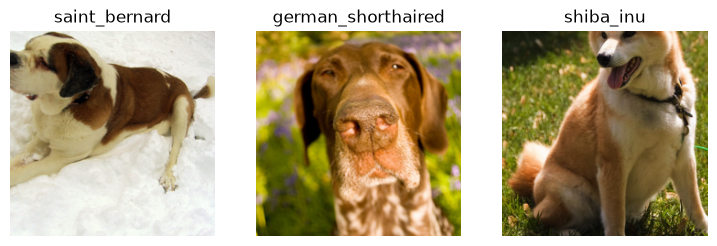

In [8]:
dls.show_batch(nrows=1, ncols=3)


Setting-up type transforms pipelines
Found 7390 items
2 datasets of sizes 5912,1478
Setting up Pipeline: PILBase.create
Setting up Pipeline: partial -> Categorize -- {'vocab': ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'boxer', 'chihuahua', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'miniature_pinscher', 'newfoundland', 'pomeranian', 'pug', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier'], 'sort': True, 'add_na': False}


Building one sample
  Pipeline: PILBase.create
    starting from
      C:\Users\Vidhy\.fastai\data\oxford-iiit-pet\images\saint_bernard_138.jpg
    applying PILBase.create gives
      PILImage mode=RGB size=50

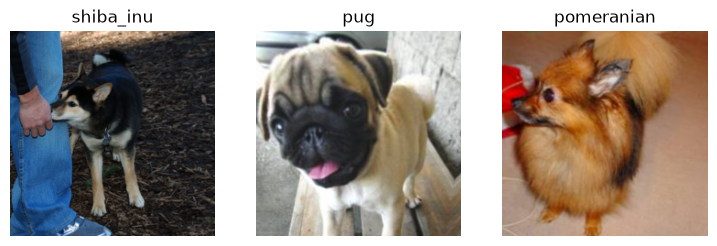

In [9]:
pets.summary(path/"images")
dls.show_batch(nrows=1, ncols=3)

In [16]:
print(learn.model[0][0].weight.device)

cuda:0


In [31]:
print(next(learn.model.parameters()).device)

cuda:0


In [25]:
import torch
import time

x = torch.randn(5000, 5000, device="cuda")
start = time.time()
y = x @ x
torch.cuda.synchronize()

print("GPU:", torch.cuda.get_device_name(0))
print("Time:", time.time() - start)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Time: 0.2281203269958496


In [32]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(25)

epoch,train_loss,valid_loss,error_rate,time
0,1.531393,0.360189,0.121110,00:59


epoch,train_loss,valid_loss,error_rate,time
0,0.467759,0.242142,0.083897,01:07
1,0.350071,0.216621,0.069012,02:02
2,0.282677,0.206828,0.071719,02:26
3,0.240529,0.230039,0.074425,01:42
4,0.219845,0.245120,0.072395,01:11
5,0.220932,0.335187,0.095399,01:09
6,0.204273,0.325245,0.093369,01:14


KeyboardInterrupt: 

In [11]:
x, y = dls.one_batch()

In [12]:
preds,_ = learn.get_preds(dl=[(x,y)])
preds[0]


<div><progress max="1" value="0"></progress> 0.00% [0/1 00:00&lt;?]</div>

tensor([6.4148e-07, 4.8845e-09, 1.8652e-09, 1.1678e-07, 1.2344e-09, 5.3602e-09,
        1.2668e-10, 4.7078e-10, 4.7772e-09, 7.0246e-07, 8.1381e-06, 2.1565e-05,
        6.1957e-09, 4.7344e-08, 1.4626e-08, 3.6874e-07, 4.8409e-08, 9.8174e-01,
        8.6815e-08, 2.4877e-09, 9.3666e-09, 1.7714e-10, 6.0424e-10, 3.7928e-08,
        3.2561e-08, 3.6302e-09, 1.8228e-02, 3.1807e-09, 3.3199e-08, 5.7405e-08,
        7.5125e-09, 1.6639e-08, 2.5073e-07, 2.6976e-07, 5.6668e-07, 1.1107e-08,
        1.3404e-07])

In [13]:
preds.sum()

tensor(64.)

[('Bengal', 'Egyptian_Mau', np.int64(6)),
 ('american_pit_bull_terrier', 'staffordshire_bull_terrier', np.int64(6)),
 ('Bombay', 'Russian_Blue', np.int64(5))]

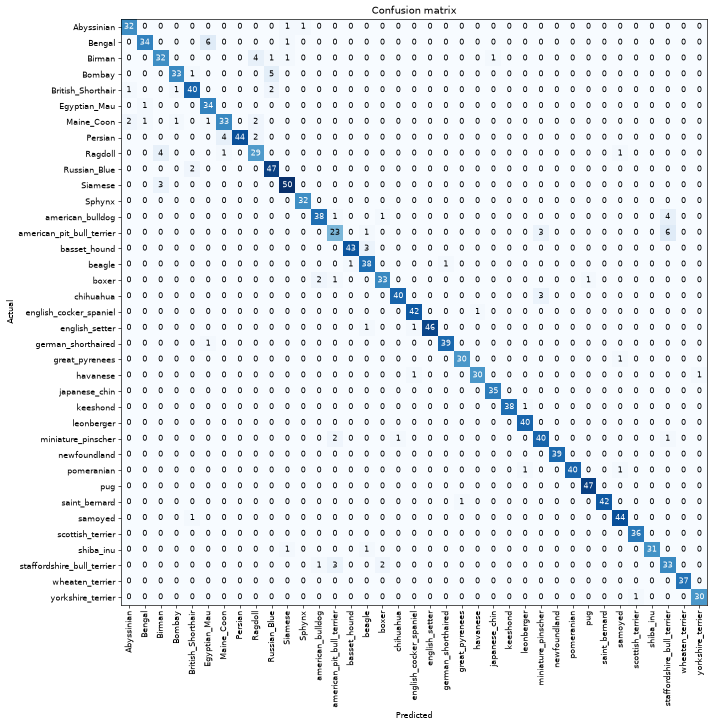

In [14]:
interp = ClassificationInterpretation.from_learner(learn)

interp.plot_confusion_matrix(
    figsize=(12,12),
    dpi=60
)

interp.most_confused(min_val=5)

In [19]:
learn = cnn_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(1, base_lr=0.1)

c:\Users\Vidhy\AppData\Local\Programs\Python\Python312\Lib\site-packages\fastai\vision\learner.py:304: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,error_rate,time
0,2.511693,4.333573,0.497294,01:03


epoch,train_loss,valid_loss,error_rate,time
0,4.062079,2.712455,0.771313,01:12


<div></div>

ValueError: not enough values to unpack (expected 2, got 1)

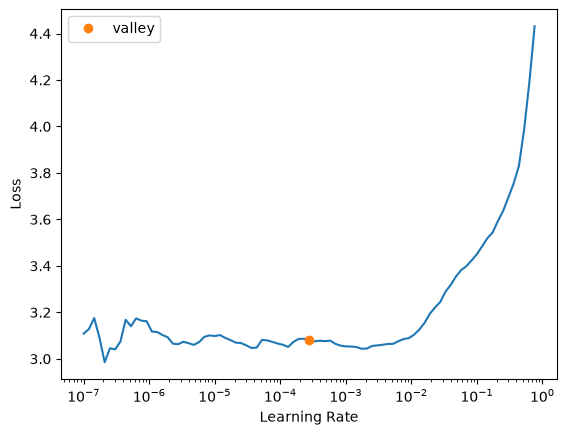

In [21]:
lr_min, lr_steep = learn.lr_find()

In [23]:
print(f"Minimum/10: , steepest point: {lr_steep:.2e}")

NameError: name 'lr_steep' is not defined

code after the baseline to imporve it   

In [ ]:
learn = cnn_learner(dls, resnet34, metrics=error_rate)
learn.fit_one_cycle(3, 3e-3)

In [ ]:
learn.unfreeze()

In [ ]:
learn.lr_find()

In [ ]:
learn.fit_one_cycle(6, lr_max=1e-5)

Discriminative Learning Rates

In [ ]:
learn = cnn_learner(dls, resnet34, metrics=error_rate)
learn.fit_one_cycle(3, 3e-3)
learn.unfreeze()
learn.fit_one_cycle(12, lr_max=slice(1e-6,1e-4))

In [ ]:
learn.recorder.plot_loss()